In [ ]:
!pip install -q rdkit

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import pandas as pd, numpy as np
from pathlib import Path

BASE = Path("/content/drive/MyDrive/kpneu_project")
IN_FILE = BASE / "data/clean/kpneu_labelled_16.csv"

print("Folder exists:", BASE.exists())
print("File exists:  ", IN_FILE.exists())

df = pd.read_csv(IN_FILE).reset_index(drop=True)
print("Shape:", df.shape, "(expected 14208 rows)")
print("Columns:", df.columns.tolist())
display(df.head(3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder exists: True
File exists:   True
Shape: (14208, 25) (expected 14208 rows)
Columns: ['can_smiles', 'mic_ugml', 'relation', 'n_meas', 'fold_range', 'conflict', 'mol_chembl_id', 'suspect_high', 'suspect_low', 'n_stereo', 'n_undefined', 'stereo_flag', 'assay_types', 'strains', 'n_assays', 'n_strains', 'strain_known', 'multi_strain', 'label', 'active', 'MW', 'logP', 'TPSA', 'HBD', 'HBA']


,can_smiles,mic_ugml,relation,n_meas,fold_range,conflict,mol_chembl_id,suspect_high,suspect_low,n_stereo,...,n_strains,strain_known,multi_strain,label,active,MW,logP,TPSA,HBD,HBA
0,Brc1cc(-c2nnc(-c3cc(Br)c(Br)[nH]3)o2)[nH]c1Br,100.0,=,1,1.0,False,CHEMBL2151450,False,False,0,...,0,False,False,inactive,0,515.785,5.1098,70.50,2.0,3.0
1,Brc1cc(-c2nnc(-c3ccccc3)o2)[nH]c1Br,100.0,=,1,1.0,False,CHEMBL2151451,False,False,0,...,0,False,False,inactive,0,369.016,4.2567,54.71,1.0,3.0
2,Brc1cc(-c2nnc(-c3ccncc3)o2)[nH]c1Br,100.0,=,1,1.0,False,CHEMBL2151453,False,False,0,...,0,False,False,inactive,0,370.004,3.6517,67.60,1.0,4.0


In [ ]:
# Leave as None to auto-detect. If detection fails, type the exact names here.
SMILES_COL = None
LABEL_COL  = None

# --- SMILES column ---
if SMILES_COL is None:
    cands = [c for c in df.columns if "smiles" in c.lower()]
    if not cands:
        raise ValueError(f"No SMILES-like column found. Columns are: {df.columns.tolist()}")
    # prefer a standardised/canonical column if several exist
    preferred = [c for c in cands if any(k in c.lower() for k in ("std", "standard", "canonical", "clean"))]
    SMILES_COL = (preferred or cands)[0]
    print("SMILES candidates:", cands)

# --- Label column ---
if LABEL_COL is None:
    def is_binary(s):
        vals = set(s.dropna().unique().tolist())
        return len(vals) == 2 and vals <= {0, 1, True, False}
    named = [c for c in df.columns
             if any(k in c.lower() for k in ("active", "label")) and is_binary(df[c])]
    anybin = [c for c in df.columns if is_binary(df[c])]
    pool = named or anybin
    if not pool:
        raise ValueError(f"No 0/1 label column found. Columns are: {df.columns.tolist()}")
    LABEL_COL = pool[0]
    print("Label candidates:", pool)

df[LABEL_COL] = df[LABEL_COL].astype(int)

print(f"\nUsing SMILES_COL = '{SMILES_COL}'")
print(f"Using LABEL_COL  = '{LABEL_COL}'")
print("Active fraction:", round(df[LABEL_COL].mean(), 3), "(expected about 0.418)")
print("Missing SMILES:", df[SMILES_COL].isna().sum())

SMILES candidates: ['can_smiles']
Label candidates: ['active']

Using SMILES_COL = 'can_smiles'
Using LABEL_COL  = 'active'
Active fraction: 0.418 (expected about 0.418)
Missing SMILES: 0


In [ ]:
from rdkit import Chem, RDLogger
from rdkit.Chem.Scaffolds import MurckoScaffold
RDLogger.DisableLog("rdApp.*")

def get_scaffold(smi):
    mol = Chem.MolFromSmiles(str(smi))
    if mol is None:
        return None
    return MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)

df["scaffold"] = df[SMILES_COL].apply(get_scaffold)

n_bad = df["scaffold"].isna().sum()
print("SMILES that failed to parse:", n_bad)
assert n_bad == 0, "Fix or drop unparseable SMILES before splitting"

print("Unique scaffolds:", df["scaffold"].nunique())
print("Acyclic molecules (empty scaffold):", (df["scaffold"] == "").sum())

SMILES that failed to parse: 0
Unique scaffolds: 4494
Acyclic molecules (empty scaffold): 303


In [ ]:
SEED = 42
FRAC = (0.8, 0.1, 0.1)

n = len(df)
n_train, n_val = int(FRAC[0] * n), int(FRAC[1] * n)
rng = np.random.RandomState(SEED)

# ---- Scaffold split: each scaffold group goes to exactly one set ----
groups = {s: list(idx) for s, idx in df.groupby("scaffold").indices.items()}
acyclic = groups.pop("", [])                      # no ring system -> train

big   = sorted([g for g in groups.values() if len(g) > n_val / 2], key=len, reverse=True)
small = [g for g in groups.values() if len(g) <= n_val / 2]
rng.shuffle(small)

train, val, test = list(acyclic), [], []
for g in big + small:
    if len(train) + len(g) <= n_train:
        train += g
    elif len(val) + len(g) <= n_val:
        val += g
    else:
        test += g

df["split_scaffold"] = ""
for name, idx in (("train", train), ("val", val), ("test", test)):
    df.loc[idx, "split_scaffold"] = name

# ---- Random split (comparison only) ----
perm = rng.permutation(n)
df["split_random"] = ""
df.loc[perm[:n_train], "split_random"] = "train"
df.loc[perm[n_train:n_train + n_val], "split_random"] = "val"
df.loc[perm[n_train + n_val:], "split_random"] = "test"

# ---- Source metadata ----
df["source"] = "ChEMBL"

assert (df["split_scaffold"] != "").all(), "Some rows missing a scaffold split"
assert (df["split_random"] != "").all(), "Some rows missing a random split"
print("Splits assigned.")

Splits assigned.


In [ ]:
for col in ["split_scaffold", "split_random"]:
    print(f"\n== {col} ==")
    out = df.groupby(col)[LABEL_COL].agg(n="count", active_frac="mean").round(3)
    out["pct_of_data"] = (out["n"] / len(df) * 100).round(1)
    print(out.loc[["train", "val", "test"]])

# Leakage check: shared scaffolds between sets (should be 0 for the scaffold split)
def overlaps(split_col):
    sc = {s: set(df.loc[df[split_col] == s, "scaffold"]) - {""} for s in ("train", "val", "test")}
    return (len(sc["train"] & sc["val"]), len(sc["train"] & sc["test"]), len(sc["val"] & sc["test"]))

print("\nShared scaffolds (train/val, train/test, val/test)")
print("  scaffold split:", overlaps("split_scaffold"), "<- must be (0, 0, 0)")
print("  random split:  ", overlaps("split_random"), "<- expected to be large")

print("\nDuplicate SMILES:", df[SMILES_COL].duplicated().sum())

# Save
OUT = BASE / "data/splits"
OUT.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT / "split_v1.csv", index=False)
print("\nSaved:", OUT / "split_v1.csv", "| rows:", len(df))


== split_scaffold ==
                    n  active_frac  pct_of_data
split_scaffold                                 
train           11366        0.425         80.0
val              1420        0.366         10.0
test             1422        0.412         10.0

== split_random ==
                  n  active_frac  pct_of_data
split_random                                 
train         11366        0.421         80.0
val            1420        0.410         10.0
test           1422        0.401         10.0

Shared scaffolds (train/val, train/test, val/test)
  scaffold split: (0, 0, 0) <- must be (0, 0, 0)
  random split:   (693, 668, 343) <- expected to be large

Duplicate SMILES: 0

Saved: /content/drive/MyDrive/kpneu_project/data/splits/split_v1.csv | rows: 14208


In [ ]:
# ---- Save clean_v1.csv: cleaned labelled data, no split columns ----
split_cols = ["scaffold", "split_scaffold", "split_random"]
clean = df.drop(columns=split_cols)          # keeps original columns + 'source'

CLEAN_OUT = BASE / "data/clean" / "clean_v1.csv"
clean.to_csv(CLEAN_OUT, index=False)
print("Saved:", CLEAN_OUT, "| rows:", len(clean), "| cols:", clean.shape[1])

# ---- Final check: both files reload and match row for row ----
c = pd.read_csv(BASE / "data/clean/clean_v1.csv")
s = pd.read_csv(BASE / "data/splits/split_v1.csv")

assert len(c) == len(s) == 14208, "Row counts differ"
assert (c[SMILES_COL] == s[SMILES_COL]).all(), "SMILES order differs"
assert (c[LABEL_COL] == s[LABEL_COL]).all(), "Labels differ"
assert set(split_cols) <= set(s.columns), "Split columns missing from split_v1"
assert not (set(split_cols) & set(c.columns)), "Split columns leaked into clean_v1"
assert c[SMILES_COL].duplicated().sum() == 0, "Duplicate SMILES"

print("\nAll checks passed.")
print("clean_v1 columns:", c.columns.tolist())
print("split_v1 extra columns:", [x for x in s.columns if x not in c.columns])

Saved: /content/drive/MyDrive/kpneu_project/data/clean/clean_v1.csv | rows: 14208 | cols: 26

All checks passed.
clean_v1 columns: ['can_smiles', 'mic_ugml', 'relation', 'n_meas', 'fold_range', 'conflict', 'mol_chembl_id', 'suspect_high', 'suspect_low', 'n_stereo', 'n_undefined', 'stereo_flag', 'assay_types', 'strains', 'n_assays', 'n_strains', 'strain_known', 'multi_strain', 'label', 'active', 'MW', 'logP', 'TPSA', 'HBD', 'HBA', 'source']
split_v1 extra columns: ['scaffold', 'split_scaffold', 'split_random']


Fingerprint matrix: (14208, 2048)
Variance explained: PC1 5.6%, PC2 2.9%, first 50 PCs 44.2%


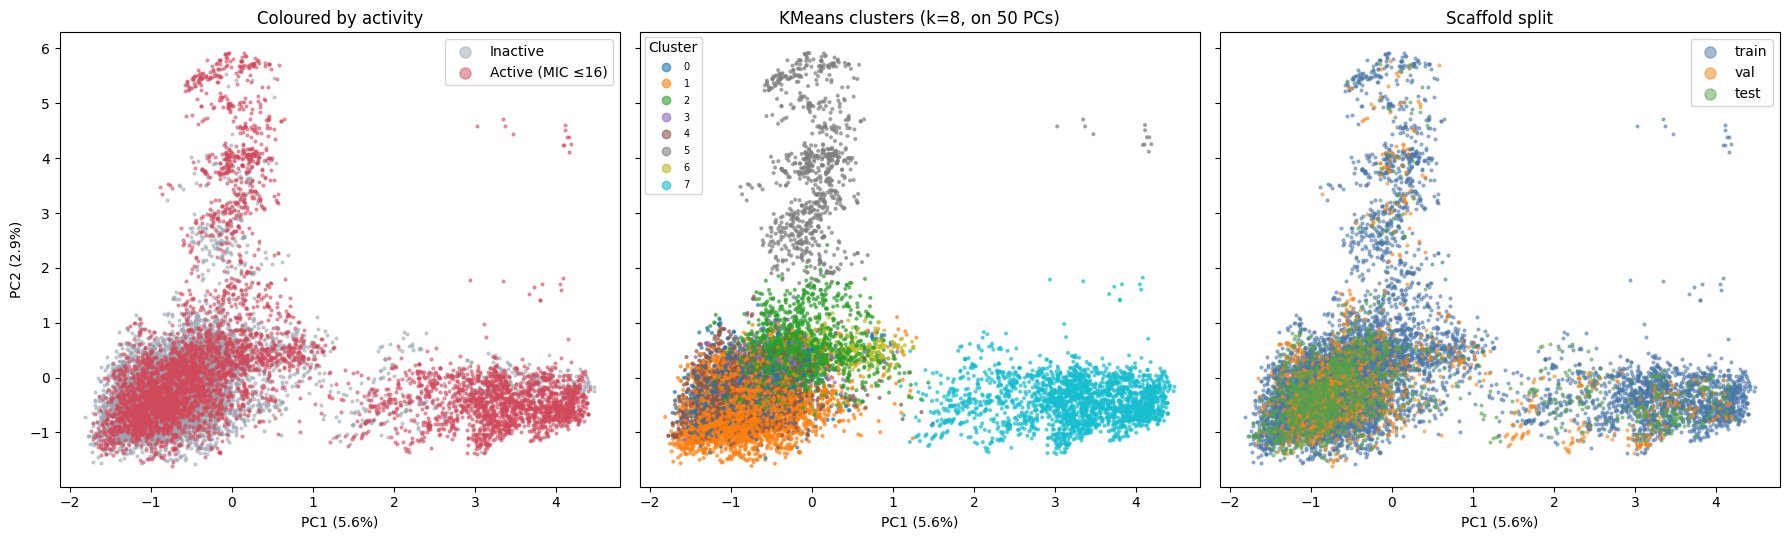

            n  active_frac
cluster                   
0         894        0.281
1        3891        0.300
2        2369        0.376
3        1311        0.315
4        2394        0.247
5         841        0.742
6         200        0.640
7        2308        0.809


In [ ]:
from rdkit.Chem import rdFingerprintGenerator
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# 1. Morgan fingerprints (ECFP4, 2048 bits)
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = np.array([gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in df[SMILES_COL]],
               dtype=np.uint8)
print("Fingerprint matrix:", fps.shape)

# 2. PCA (50 components for clustering, first 2 for plotting)
pca = PCA(n_components=50, random_state=42)
pcs = pca.fit_transform(fps)
print(f"Variance explained: PC1 {pca.explained_variance_ratio_[0]:.1%}, "
      f"PC2 {pca.explained_variance_ratio_[1]:.1%}, "
      f"first 50 PCs {pca.explained_variance_ratio_.sum():.1%}")

# 3. KMeans on the 50 PCs
K = 8
df["cluster"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(pcs)
df["pc1"], df["pc2"] = pcs[:, 0], pcs[:, 1]

# 4. Three-panel plot
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)

for lab, name, col in [(0, "Inactive", "#9aa5b1"), (1, "Active (MIC ≤16)", "#d1495b")]:
    m = df[LABEL_COL] == lab
    ax[0].scatter(df.loc[m, "pc1"], df.loc[m, "pc2"], s=4, alpha=0.5, c=col, label=name)
ax[0].set_title("Coloured by activity"); ax[0].legend(markerscale=4)

sc = ax[1].scatter(df["pc1"], df["pc2"], s=4, alpha=0.6, c=df["cluster"], cmap="tab10")
ax[1].set_title(f"KMeans clusters (k={K}, on 50 PCs)")
ax[1].legend(*sc.legend_elements(), title="Cluster", markerscale=1, fontsize=7, loc="best")

for s, col in [("train", "#4c78a8"), ("val", "#f58518"), ("test", "#54a24b")]:
    m = df["split_scaffold"] == s
    ax[2].scatter(df.loc[m, "pc1"], df.loc[m, "pc2"], s=4, alpha=0.5, c=col, label=s)
ax[2].set_title("Scaffold split"); ax[2].legend(markerscale=4)

for a in ax:
    a.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.tight_layout()

PLOTS = BASE / "plots"          # change if your Day 3 plots live elsewhere
PLOTS.mkdir(exist_ok=True)
plt.savefig(PLOTS / "day4_pca_kmeans.png", dpi=200, bbox_inches="tight")
plt.show()

# 5. Active rate and size per cluster
print(df.groupby("cluster")[LABEL_COL].agg(n="count", active_frac="mean").round(3))